# CS228 – Face Spoofing Analysis: FaceNet baseline + MiniFASNetV2 PAD on CelebA-Spoof

**Pipeline**
1. **Setup** (facenet-pytorch for base model, Silent-Face-Anti-Spoofing for PAD, CelebA-Spoof dataset for testing)
2. **Load + audit annotations** (missing values, label sanity)
3. **Subject-disjoint stratified subsample** (so there's no need to unzip all 625,537 images)
4. **Selective extraction of only the sampled files** (works on a zip or split zip parts, without unzipping everything)
5. **One-pass preprocessing:** BBox crop to two cached arrays (160x160 for FaceNet, 80x80 scale-2.7 for MiniFASNetV2)
6. **Baseline:** FaceNet (InceptionResnetV1, VGGFace2) embeddings -> logistic regression (+ optional PCA)
7. **MiniFASNetV2 zero-shot PAD**
8. **Metrics (AUC, EER, APCER, BPCER, ACER) overall and per spoof type**
9. **Extras:** does a spoof fool FaceNet identity matching? MTCNN detection rate on spoofs
10. **Pipeline comparison: FaceNet alone vs FaceNet + MiniFASNetV2** (FRR / FAR / IAPMR, per attack type)

> Positive class = **spoof (attack)**. APCER = attacks accepted as live. BPCER = live rejected as attack.

## Terminology in the notebook:
Spoof-detection metrics (positive = spoof)

- APCER: Attack Presentation Classification Error Rate, the fraction of spoofs wrongly accepted as live.
- BPCER: Bona Fide Presentation Classification Error Rate, the fraction of real live faces wrongly flagged as spoofs.
- ACER: Average Classification Error Rate, the average of APCER and BPCER.
- EER: Equal Error Rate, the point where the two kinds of error are equal. Lower is better.
- ROC: Receiver Operating Characteristic, the curve of true-positive rate (TPR) against false-positive rate (FPR) as you vary the threshold.
- AUC: Area Under the ROC Curve. 1.0 is perfect and 0.5 is a coin flip.

Verification metrics

- FRR: False Reject Rate, the share of genuine users turned away.
- FAR: False Accept Rate, the share of impostors (a different person’s live face) let in.
- IAPMR: Impostor Attack Presentation Match Rate, the share of spoof attacks on an enrolled person that get accepted.
- “HTER-like”: the column name in the comparison table. The standard HTER (Half Total Error Rate) averages FAR and FRR. My version averages FRR, FAR and IAPMR, so it isn't exactly HTER.

## 1. Setup

In [ ]:
!pip -q install facenet-pytorch --no-deps
!pip -q install opencv-python-headless scikit-learn pandas matplotlib tqdm
!test -d Silent-Face-Anti-Spoofing || git clone -q https://github.com/minivision-ai/Silent-Face-Anti-Spoofing.git
!ls Silent-Face-Anti-Spoofing/resources/anti_spoof_models

2.7_80x80_MiniFASNetV2.pth  4_0_0_80x80_MiniFASNetV1SE.pth


In [ ]:
import os, re, io, sys, json, glob, zipfile, shutil, random
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, roc_auc_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

from google.colab import drive
drive.mount('/content/drive')

device: cuda
Mounted at /content/drive


### Config
`CELEBA_DIR` is only a starting guess. The next cell **searches your Drive** for the label JSONs, the archive parts and the `Data/` folder, prints what it finds, and configures everything automatically.
Note: Colab only sees *My Drive*. If the dataset is in "Shared with me", right-click it in Drive and choose *Organize > Add shortcut* to put it in My Drive first.
Sample sizes are the main knob for Colab limits: 6k train / 3k test by default (about 9k images total); the cached crops are small, and originals are never written to disk.

In [ ]:
CELEBA_DIR = '/content/drive/MyDrive/CelebA_Spoof'   # starting guess only; auto-search below if this is wrong

N_TRAIN, N_TEST = 6000, 3000       # images sampled from train_label.json / test_label.json
LIVE_FRAC       = 0.5             # balance live/spoof in the subset (natural ratio is ~1:2)
CAP_PER_SUBJECT = 20              # max images per identity -> more identities, less leakage
SEED            = 42

WORK   = '/content/work'          # cached arrays (local disk = fast)
SUBSET = '/content/subset'        # extracted originals for the sample only (overridden in folder mode)
os.makedirs(WORK, exist_ok=True); os.makedirs(SUBSET, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

### Locate the dataset (auto)

In [ ]:
class MultiPartFile:
    """Read-only, seekable view over several split-archive parts (.zip.001, .zip.002, ...)."""
    def __init__(self, paths):
        self.f = [open(p, 'rb') for p in paths]
        self.offs = np.cumsum([0] + [os.path.getsize(p) for p in paths]).astype(np.int64)
        self.total, self.pos = int(self.offs[-1]), 0
    def seekable(self): return True
    def tell(self): return self.pos
    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.total + off)
        return self.pos
    def read(self, n=-1):
        n = self.total - self.pos if n is None or n < 0 else n
        out = []
        while n > 0 and self.pos < self.total:
            i = int(np.searchsorted(self.offs, self.pos, side='right') - 1)
            self.f[i].seek(self.pos - int(self.offs[i]))
            chunk = self.f[i].read(min(n, int(self.offs[i + 1]) - self.pos))
            if not chunk: break
            out.append(chunk); self.pos += len(chunk); n -= len(chunk)
        return b''.join(out)

def walk_find(root, pred, maxdepth=5):
    hits, base = [], root.rstrip('/').count('/')
    for dp, dn, fn in os.walk(root):
        if dp.count('/') - base >= maxdepth: dn[:] = []
        dn[:] = [d for d in dn if not d.startswith('.')]
        for n in dn + fn:
            p = os.path.join(dp, n)
            if pred(p, n): hits.append(p)
        dn[:] = [d for d in dn if d != 'Data']          # never descend into the huge image folder
    return hits

DRIVE = '/content/drive/MyDrive'
assert os.path.isdir(DRIVE), 'Drive is not mounted - re-run the mount cell'
print('Top level of My Drive:', sorted(os.listdir(DRIVE))[:60])
def last4(k): return '/'.join(k.split('/')[-4:])        # train/<id>/live/000001.jpg

roots = [CELEBA_DIR if os.path.isdir(CELEBA_DIR) else DRIVE]
if os.path.isdir('/content/drive/.shortcut-targets-by-id'): roots.append('/content/drive/.shortcut-targets-by-id')   # folders added as shortcuts
print('searching under:', roots)

jsons = sum([walk_find(r, lambda p, n: n in ('train_label.json', 'test_label.json')) for r in roots], [])
is_zip = lambda n: re.search(r'\.zip(\.\d+)?$', n) is not None
zips  = sum([walk_find(r, lambda p, n: is_zip(n) and re.search('celeba|spoof', p, re.I) is not None) for r in roots], [])
if not zips: zips = sum([walk_find(r, lambda p, n: is_zip(n)) for r in roots], [])      # fallback: any zip
datad = sum([walk_find(r, lambda p, n: n == 'Data' and os.path.isdir(p + '/train')) for r in roots], [])
print('label JSONs :', jsons); print('archive files:', zips); print('Data folders :', datad)

# split parts (.zip.001, .002 ...) form ONE archive; plain .zip files are each their own archive
groups = {}
for z in zips: groups.setdefault(re.sub(r'\.\d+$', '', z), []).append(z)
ARCHIVES = [sorted(g) for g in groups.values()]
print(f'{len(ARCHIVES)} archive(s):', [(os.path.basename(g[0]), len(g)) for g in ARCHIVES])

def open_archive(i):
    parts = ARCHIVES[i]
    return zipfile.ZipFile(parts[0] if (len(parts) == 1 and parts[0].endswith('.zip')) else MultiPartFile(parts))

# index every archive once: last4(member) -> (archive_idx, member_name)
ZINDEX, ZNAMES = {}, []
for i in range(len(ARCHIVES)):
    with open_archive(i) as z:
        names = z.namelist()
    ZNAMES.append(names)
    for n in names:
        if n.lower().endswith(('.jpg', '.jpeg', '.png', '.txt')): ZINDEX[last4(n)] = (i, n)
print(f'indexed {sum(k.endswith(".jpg") for k in ZINDEX):,} images across archives')

def pick(name):
    c = sorted([p for p in jsons if os.path.basename(p) == name], key=lambda p: 'intra_test' not in p)
    return c[0] if c else None
TRAIN_JSON, TEST_JSON = pick('train_label.json'), pick('test_label.json')

if TRAIN_JSON is None and ARCHIVES:               # labels may only exist inside an archive
    print('label JSONs not found on disk - looking inside the archives ...')
    def pick_zip(name):
        c = sorted([(i, n) for i, ns in enumerate(ZNAMES) for n in ns if n.endswith('/' + name) or n == name],
                   key=lambda t: 'intra_test' not in t[1])
        return f'zip::{c[0][0]}::{c[0][1]}' if c else None
    TRAIN_JSON, TEST_JSON = pick_zip('train_label.json'), pick_zip('test_label.json')

DATA_MODE = 'zip' if ARCHIVES else 'folder'
if DATA_MODE == 'folder':
    assert datad, ('Could not find archive files or a Data/ folder with train/ inside it. '
                   'Check the listing above: is CelebA-Spoof actually in My Drive (not only Shared with me)?')
    SUBSET = datad[0]
assert TRAIN_JSON and TEST_JSON, ('train_label.json / test_label.json not found on disk or in the archive. '
                                  'Download the metas folder from the CelebA-Spoof repo links and put it in Drive.')
print('\nDATA_MODE =', DATA_MODE, '\nTRAIN_JSON =', TRAIN_JSON, '\nTEST_JSON  =', TEST_JSON, '\nSUBSET     =', SUBSET)

def read_json(p):
    if p.startswith('zip::'):
        _, i, name = p.split('::', 2)
        with open_archive(int(i)) as z: return json.loads(z.read(name))
    return json.load(open(p))

Top level of My Drive: ['200W Movie Summary.gdoc', 'CS 228 Biometric Security and AI Notes.gdoc', 'CS 228 Project Proposal.gdoc', 'CS 262 Randomized Algorithms Notes.gdoc', 'CS 262 Topics in AI', 'CS-200W Assignment 3.gdoc', 'CS-200W Presentation Script.gdoc', 'CS-200W TAS Presentation.gslides', 'CS-228-01 Biometric Security with AI presentation October 1.gslides', 'CS200W Cover Letter Assignment.gdoc', 'CS200W Resume Final Draft.gdoc', 'CS200W Writing Exercise 2.gdoc', 'CS228-01 Assignment 1 Report.gdoc', 'CS228_Research_Project', 'Colab Notebooks', 'Colab_Notebooks', 'ROUGH DRAFT CS 228 Project Proposal.gdoc', 'SJSU AI literacy.gdoc', 'Thomas Tran Icebreaker Slide.gslides', 'Thomas and Anna Schedule.gdoc', 'ThomasTranResume.gdoc', 'Topics In AI Assignment 2.gdoc', 'Topics in AI Assignment 1.gdoc', 'Topics in AI Assignment 3 (Research Problem & Question).gdoc', 'Topics in AI Assignment 4.gdoc', 'Topics in AI Assignment 5.gdoc', 'Topics in AI Assignment 6.gdoc', 'Topics in AI Assignmen

## 2. Load and audit annotations
Per the dataset spec each entry is a 44-long list: `[0:40]` face attributes, `[40]` spoof type, `[41]` illumination, `[42]` environment, `[43]` live/spoof.
(Spoof types: 0 live, 1 Photo, 2 Poster, 3 A4, 4 Face Mask, 5 Upper Body Mask, 6 Region Mask, 7 PC, 8 Pad, 9 Phone, 10 3D Mask.)

In [ ]:
# NOTE: names assume the standard CelebA attribute order; the spec itself doesn't name them.
ATTRS = ['5_o_Clock_Shadow','Arched_Eyebrows','Attractive','Bags_Under_Eyes','Bald','Bangs','Big_Lips','Big_Nose',
 'Black_Hair','Blond_Hair','Blurry','Brown_Hair','Bushy_Eyebrows','Chubby','Double_Chin','Eyeglasses','Goatee','Gray_Hair',
 'Heavy_Makeup','High_Cheekbones','Male','Mouth_Slightly_Open','Mustache','Narrow_Eyes','No_Beard','Oval_Face','Pale_Skin',
 'Pointy_Nose','Receding_Hairline','Rosy_Cheeks','Sideburns','Smiling','Straight_Hair','Wavy_Hair','Wearing_Earrings',
 'Wearing_Hat','Wearing_Lipstick','Wearing_Necklace','Wearing_Necktie','Young']
assert len(ATTRS) == 40
SPOOF_NAMES = {0:'Live',1:'Photo',2:'Poster',3:'A4',4:'FaceMask',5:'UpperBodyMask',6:'RegionMask',7:'PC',8:'Pad',9:'Phone',10:'3DMask'}

def load_meta(path):
    d = read_json(path)
    bad = [k for k, v in d.items() if v is None or len(v) != 44]
    print(f'{os.path.basename(path)}: {len(d):,} entries, {len(bad)} malformed (dropped)')
    good = [k for k in d if k not in set(bad)]
    A = np.array([d[k] for k in good], dtype=np.float32)
    df = pd.DataFrame(A[:, :40], columns=ATTRS)
    df['spoof_type'], df['illum'], df['env'], df['is_spoof'] = A[:,40].astype(int), A[:,41].astype(int), A[:,42].astype(int), A[:,43].astype(int)
    df['key'] = good
    df['rel'] = [last4(k) for k in good]
    df['subject'] = [k.split('/')[-3] for k in good]
    return df

train_all = load_meta(TRAIN_JSON)
test_all  = load_meta(TEST_JSON)

train_label.json: 494,405 entries, 0 malformed (dropped)
test_label.json: 67,170 entries, 0 malformed (dropped)


In [ ]:
def audit(df, name):
    print(f'--- {name} ---')
    print('NaN cells:', int(df.isna().sum().sum()), '| duplicate keys:', int(df.key.duplicated().sum()))
    print('is_spoof values:', sorted(df.is_spoof.unique()), '| spoof_type values:', sorted(df.spoof_type.unique()))
    print('illum values:', sorted(df.illum.unique()), '| env values:', sorted(df.env.unique()))
    # live/spoof must agree with spoof_type
    mism = ((df.spoof_type > 0).astype(int) != df.is_spoof).sum()
    print('label inconsistencies (spoof_type vs is_spoof):', int(mism))
    # attributes should be binary; some CelebA dumps use -1/1
    vals = np.unique(df[ATTRS].values)
    print('attribute value set:', vals)
    print(f'subjects: {df.subject.nunique():,} | live: {(df.is_spoof==0).sum():,} | spoof: {(df.is_spoof==1).sum():,}')

for d, n in [(train_all, 'train'), (test_all, 'test')]:
    if (d[ATTRS].values < 0).any(): d[ATTRS] = (d[ATTRS] > 0).astype(np.float32)   # normalise -1/1 -> 0/1
    audit(d, n)
    d.drop(d[(d.spoof_type > 0).astype(int) != d.is_spoof].index, inplace=True)       # drop inconsistent rows, if any

print(train_all.spoof_type.map(SPOOF_NAMES).value_counts())

--- train ---
NaN cells: 0 | duplicate keys: 0
is_spoof values: [np.int64(0), np.int64(1)] | spoof_type values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
illum values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | env values: [np.int64(0), np.int64(1), np.int64(2)]
label inconsistencies (spoof_type vs is_spoof): 0
attribute value set: [0. 1.]
subjects: 8,192 | live: 162,462 | spoof: 331,943
--- test ---
NaN cells: 0 | duplicate keys: 0
is_spoof values: [np.int64(0), np.int64(1)] | spoof_type values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
illum values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | env values: [np.int64(0), np.int64(1), np.int64(2)]
label inconsistencies (spoof_type vs is_spoof): 0
attribute value set: [0. 1.]
subjects: 1,

## 3. Subject-disjoint, stratified subsample
- Cap images per identity (more identities, less memorisation).
- Balance live vs spoof, and spread spoof samples evenly across the 10 attack types (rare types like 3D mask are kept whole).
- Train/val are split **by subject**; test comes from the official `test_label.json` (disjoint identities).

{'train': 5109, 'val': 891, 'test': 3000}


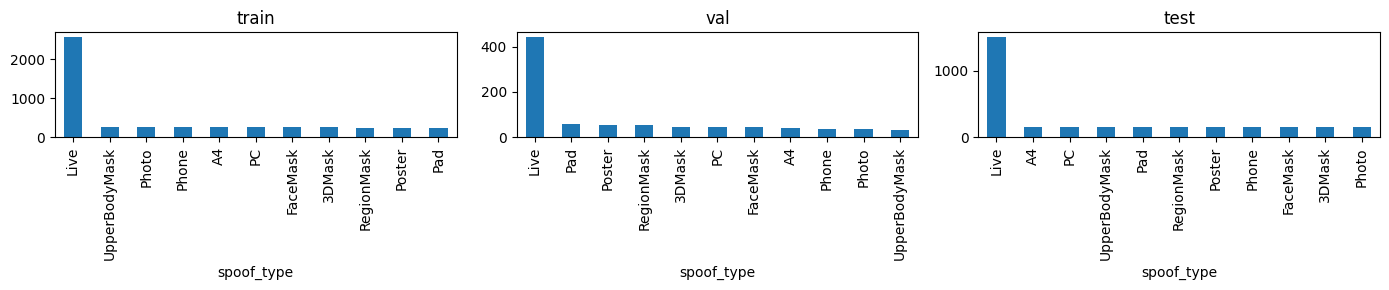

In [ ]:
def subsample(df, n, live_frac=LIVE_FRAC, cap=CAP_PER_SUBJECT, seed=SEED):
    d = df.sample(frac=1, random_state=seed)
    d = d[d.groupby('subject').cumcount() < cap]
    n_live = int(n * live_frac); n_sp = n - n_live
    live = d[d.is_spoof == 0].head(n_live)
    sp = d[d.is_spoof == 1]
    types = sorted(sp.spoof_type.unique()); per = n_sp // len(types)
    parts = [sp[sp.spoof_type == t].head(per) for t in types]
    chosen = pd.concat(parts)
    short = n_sp - len(chosen)                          # top up if some types were rare
    if short > 0: chosen = pd.concat([chosen, sp.drop(chosen.index).head(short)])
    return pd.concat([live, chosen]).sample(frac=1, random_state=seed).reset_index(drop=True)

tr_pool = subsample(train_all, N_TRAIN)
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_i, va_i = next(gss.split(tr_pool, groups=tr_pool.subject))
train, val = tr_pool.iloc[tr_i].reset_index(drop=True), tr_pool.iloc[va_i].reset_index(drop=True)
test = subsample(test_all, N_TEST)
assert not set(train.subject) & set(val.subject), 'subject leakage train/val'
print({k: len(v) for k, v in dict(train=train, val=val, test=test).items()})

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, (n, d) in zip(ax, [('train', train), ('val', val), ('test', test)]):
    d.spoof_type.map(SPOOF_NAMES).value_counts().plot.bar(ax=a, title=n)
plt.tight_layout(); plt.show()

## 4. Stream from the archives (no originals written to disk)
Earlier versions extracted the sampled originals first. Now each sampled image is **read from the archive into memory, cropped, and only the small crops are kept**.
That removes our own disk use. The other disk consumer is Google Drive's local read-cache for the huge zips, so the loop below also watches free space and, if it runs low, flushes and remounts Drive (which should release that cache) and retries the chunk.

In [ ]:
def free_gb(): return shutil.disk_usage('/content').free / 1e9

def recycle_drive():
    print(f'free disk {free_gb():.1f} GB -> flushing and remounting Drive to release its local cache')
    drive.flush_and_unmount(); drive.mount('/content/drive')

CHUNK, MIN_FREE_GB = 1500, 8          # images per chunk; remount Drive when free disk drops below this

if DATA_MODE == 'zip':                # clear leftovers from any earlier (failed) extraction
    shutil.rmtree(SUBSET, ignore_errors=True); os.makedirs(SUBSET, exist_ok=True)
print(f'free disk now: {free_gb():.1f} GB')

free disk now: 75.1 GB


## 5. Preprocessing: crop / alignment / normalisation (one pass, cached)
- **BBox**: CelebA-Spoof's `_BB.txt` stores `x y w h` relative to a 224x224 rescale, so it is mapped back to the real image size.
- **FaceNet input**: BBox + 15% margin, resized to 160x160, RGB, cached as uint8. Standardisation `(x-127.5)/128` is applied at inference time.
- **MiniFASNetV2 input**: crop at **scale 2.7** around the box (context matters for spoof cues), resized to 80x80, **BGR**, values kept in 0-255 (this model's `ToTensor` does not divide by 255).
- Failures (unreadable image, missing/degenerate BBox) are flagged in a `valid` mask and dropped.

Face alignment: the dataset's box is used for speed/determinism. If you want landmark alignment, the MTCNN cell near the end shows how well it detects faces on spoofs.

In [ ]:
def parse_bb(txt, W, H):
    v = txt.split()
    if len(v) < 4: return None
    x, y, w, h = [float(t) for t in v[:4]]
    x, y, w, h = int(x * W / 224), int(y * H / 224), int(w * W / 224), int(h * H / 224)
    x, y = max(x, 0), max(y, 0)
    w, h = min(w, W - x), min(h, H - y)
    return (x, y, w, h) if w > 8 and h > 8 else None

def read_bbox(img_path, W, H):
    p = re.sub(r'\.\w+$', '_BB.txt', img_path)
    return parse_bb(open(p).read(), W, H) if os.path.exists(p) else None

def crop_margin(img, bb, margin=0.15, size=160):
    x, y, w, h = bb; H, W = img.shape[:2]; m = int(max(w, h) * margin)
    c = img[max(y-m, 0):min(y+h+m, H), max(x-m, 0):min(x+w+m, W)]
    return cv2.resize(c, (size, size), interpolation=cv2.INTER_AREA)

def crop_scaled(img, bb, scale=2.7, size=80):
    # re-implementation of Silent-Face's CropImage (same box maths)
    H, W = img.shape[:2]; x, y, bw, bh = bb
    scale = min((H - 1) / bh, min((W - 1) / bw, scale))
    nw, nh = bw * scale, bh * scale
    cx, cy = bw / 2 + x, bh / 2 + y
    l, t, r, b = cx - nw / 2, cy - nh / 2, cx + nw / 2, cy + nh / 2
    if l < 0: r -= l; l = 0
    if t < 0: b -= t; t = 0
    if r > W - 1: l -= r - W + 1; r = W - 1
    if b > H - 1: t -= b - H + 1; b = H - 1
    c = img[int(t):int(b) + 1, int(l):int(r) + 1]
    return cv2.resize(c, (size, size))

def make_crops(img, bb):
    f160 = cv2.cvtColor(crop_margin(img, bb), cv2.COLOR_BGR2RGB)
    return f160, crop_scaled(img, bb)          # f80 stays BGR

def sample_from_disk(rel):
    p = f'{SUBSET}/{rel}'
    img = cv2.imread(p)                         # BGR
    if img is None: return None
    H, W = img.shape[:2]; bb = read_bbox(p, W, H)
    return None if bb is None else make_crops(img, bb)

def sample_from_bytes(img_bytes, bb_bytes):
    img = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
    if img is None: return None
    H, W = img.shape[:2]; bb = parse_bb(bb_bytes.decode('utf-8', 'ignore'), W, H)
    return None if bb is None else make_crops(img, bb)

def process(df, name):
    N, rels = len(df), df.rel.tolist()
    a160 = np.lib.format.open_memmap(f'{WORK}/{name}_f160.npy', 'w+', np.uint8, (N, 160, 160, 3))
    a80  = np.lib.format.open_memmap(f'{WORK}/{name}_f80.npy',  'w+', np.uint8, (N, 80, 80, 3))
    ok = np.zeros(N, bool)
    def store(i, r):
        if r is None: return
        a160[i], a80[i] = r; ok[i] = True
    pool = ThreadPoolExecutor(8)
    if DATA_MODE == 'folder':
        list(tqdm(pool.map(lambda i: store(i, sample_from_disk(rels[i])), range(N)), total=N, desc=name))
    else:
        jobs, missing = {}, 0
        for i, r in enumerate(rels):
            tb = re.sub(r'\.\w+$', '_BB.txt', r)
            if r in ZINDEX and tb in ZINDEX and ZINDEX[r][0] == ZINDEX[tb][0]:
                jobs.setdefault(ZINDEX[r][0], []).append((i, ZINDEX[r][1], ZINDEX[tb][1]))
            else: missing += 1
        if missing: print(f'{name}: {missing} samples have no image/BBox in the archives (dropped)')
        bar = tqdm(total=N - missing, desc=name)
        for a, items in jobs.items():
            z = open_archive(a)
            items.sort(key=lambda t: z.getinfo(t[1]).header_offset)          # near-sequential reads
            s0, fails = 0, 0
            while s0 < len(items):
                chunk = items[s0:s0 + CHUNK]
                try:
                    futs = [pool.submit(lambda i, ib, bb: store(i, sample_from_bytes(ib, bb)), i, z.read(m_img), z.read(m_bb))
                            for i, m_img, m_bb in chunk]
                    for f in futs: f.result()
                except OSError as e:
                    if e.errno != 28: raise
                    fails += 1
                    if fails > 2: raise RuntimeError('Disk still full after remounting Drive. Lower N_TRAIN/N_TEST, or use a high-disk runtime.') from e
                    z.close(); recycle_drive(); z = open_archive(a); continue   # retry the same chunk
                s0 += CHUNK; fails = 0; bar.update(len(chunk))
                if free_gb() < MIN_FREE_GB:
                    z.close(); recycle_drive(); z = open_archive(a)
            z.close()
        bar.close()
    pool.shutdown()
    a160.flush(); a80.flush()
    print(f'{name}: {ok.sum():,}/{N:,} valid ({(~ok).sum()} dropped)')
    return ok

splits = {}
for name, df in [('train', train), ('val', val), ('test', test)]:
    ok = process(df, name)
    df['valid'] = ok
    df.to_csv(f'{WORK}/{name}_meta.csv', index=False)
    splits[name] = df

train:   0%|          | 0/5109 [00:00<?, ?it/s]

train: 5,107/5,109 valid (2 dropped)


val:   0%|          | 0/891 [00:00<?, ?it/s]

val: 891/891 valid (0 dropped)


test:   0%|          | 0/3000 [00:00<?, ?it/s]

free disk 0.9 GB -> flushing and remounting Drive to release its local cache
Mounted at /content/drive
test: 2,999/3,000 valid (1 dropped)


train (5107, 160, 160, 3) (5107, 80, 80, 3)
val (891, 160, 160, 3) (891, 80, 80, 3)
test (2999, 160, 160, 3) (2999, 80, 80, 3)


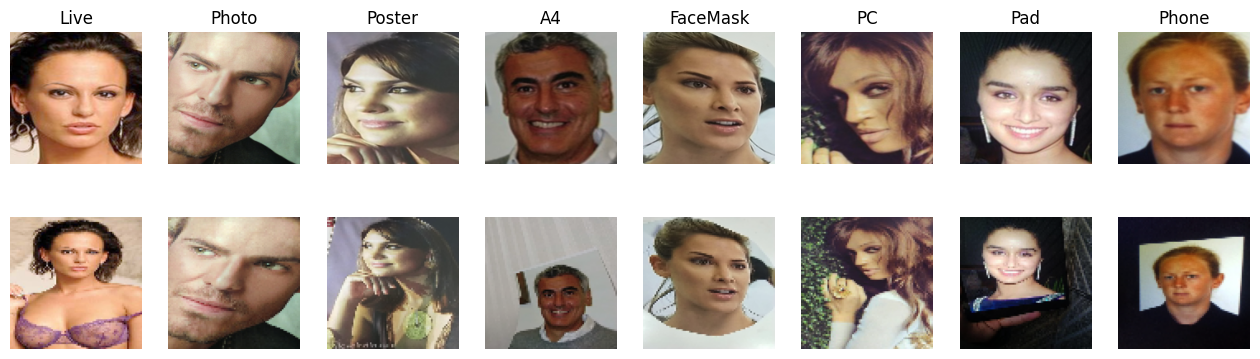

In [ ]:
# Load cached arrays and keep valid rows only
D = {}
for name, df in splits.items():
    m = df.valid.values
    D[name] = dict(
        f160=np.load(f'{WORK}/{name}_f160.npy', mmap_mode='r')[m],
        f80=np.load(f'{WORK}/{name}_f80.npy',  mmap_mode='r')[m],
        meta=df[m].reset_index(drop=True))
    print(name, D[name]['f160'].shape, D[name]['f80'].shape)

# sanity-check crops
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
m = D['test']['meta']; pick = [m[m.spoof_type == t].index[0] for t in [0,1,2,3,4,7,8,9] if (m.spoof_type == t).any()]
for j, i in enumerate(pick[:8]):
    ax[0, j].imshow(D['test']['f160'][i]); ax[0, j].set_title(SPOOF_NAMES[m.spoof_type[i]]); ax[0, j].axis('off')
    ax[1, j].imshow(D['test']['f80'][i][..., ::-1]); ax[1, j].axis('off')
plt.show()

# optional: copy cache to Drive so you can skip steps 3-5 next session
# shutil.copytree(WORK, '/content/drive/MyDrive/CelebA_Spoof_cache', dirs_exist_ok=True)

## 6. Feature analysis: is reduction needed?
- The 40 face attributes are **not** model inputs here. They describe identity/appearance, so using them as features would be leakage-prone. They're kept for slicing/fairness analysis. A correlation check shows which are redundant if you do want them.
- The FaceNet embedding is 512-d. PCA is evaluated empirically below, and kept only if it doesn't hurt.

In [ ]:
C = train[ATTRS].corr().abs()
pairs = [(a, b, C.loc[a, b]) for i, a in enumerate(ATTRS) for b in ATTRS[i+1:] if C.loc[a, b] > 0.8]
print('highly correlated attribute pairs (|r|>0.8):', pairs or 'none')
print('constant / near-constant attributes:', [a for a in ATTRS if train[a].std() < 0.02] or 'none')

highly correlated attribute pairs (|r|>0.8): [('Heavy_Makeup', 'Wearing_Lipstick', np.float64(0.860990953316339))]
constant / near-constant attributes: none


## 7. FaceNet baseline: embeddings -> live/spoof classifier

In [ ]:
from facenet_pytorch import InceptionResnetV1
resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

@torch.no_grad()
def facenet_embed(f160, bs=256):
    out = []
    for i in tqdm(range(0, len(f160), bs), leave=False):
        x = torch.from_numpy(np.ascontiguousarray(f160[i:i+bs])).permute(0, 3, 1, 2).float()
        x = ((x - 127.5) / 128.0).to(device)                     # fixed image standardisation
        out.append(resnet(x).cpu().numpy())
    return np.concatenate(out)

for k in D: D[k]['emb'] = facenet_embed(D[k]['f160']); print(k, D[k]['emb'].shape)
np.savez_compressed(f'{WORK}/embeddings.npz', **{k: D[k]['emb'] for k in D})

  0%|          | 0.00/107M [00:00<?, ?B/s]

  0%|          | 0/20 [00:00<?, ?it/s]

train (5107, 512)


  0%|          | 0/4 [00:00<?, ?it/s]

val (891, 512)


  0%|          | 0/12 [00:00<?, ?it/s]

test (2999, 512)


In [ ]:
def pad_metrics(y, s, thr=None):
    """y: 1=spoof. s: spoof score (higher = more spoof)."""
    fpr, tpr, th = roc_curve(y, s); fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr)); eer, thr_eer = (fpr[i] + fnr[i]) / 2, th[i]
    t = thr_eer if thr is None else thr
    pred = s >= t
    apcer = float((~pred[y == 1]).mean()); bpcer = float(pred[y == 0].mean())
    return dict(AUC=roc_auc_score(y, s), EER=eer, thr=float(t), APCER=apcer, BPCER=bpcer, ACER=(apcer + bpcer) / 2)

def per_type_apcer(meta, s, thr):
    rows = {}
    for t in range(1, 11):
        m = (meta.spoof_type == t).values
        if m.sum(): rows[SPOOF_NAMES[t]] = dict(n=int(m.sum()), APCER=float((s[m] < thr).mean()))
    return pd.DataFrame(rows).T

y = {k: D[k]['meta'].is_spoof.values for k in D}
results = {}

def run_clf(name, clf):
    clf.fit(D['train']['emb'], y['train'])
    sv, st = clf.predict_proba(D['val']['emb'])[:, 1], clf.predict_proba(D['test']['emb'])[:, 1]
    thr = pad_metrics(y['val'], sv)['thr']                 # threshold picked on val (EER), applied to test
    results[name] = pad_metrics(y['test'], st, thr); return st, thr

st_lr,  thr_lr  = run_clf('FaceNet emb + LogReg', make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced')))
st_pca, thr_pca = run_clf('FaceNet emb + PCA(95%) + LogReg', make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED), LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced')))
pca = make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED)).fit(D['train']['emb']); print('PCA components for 95% variance:', pca[-1].n_components_, 'of 512')
pd.DataFrame(results).T

PCA components for 95% variance: 45 of 512


,AUC,EER,thr,APCER,BPCER,ACER
FaceNet emb + LogReg,0.694636,0.363788,0.486753,0.392667,0.328886,0.360776
FaceNet emb + PCA(95%) + LogReg,0.660837,0.388796,0.490351,0.409333,0.354903,0.382118


## 8. MiniFASNetV2 PAD (Silent-Face-Anti-Spoofing)
Uses the repo's pretrained `2.7_80x80_MiniFASNetV2.pth`. The model outputs 3 logits; **class 1 = real**, classes 0 and 2 = attack types. Spoof score = `1 - P(real)`.
This is **zero-shot**: the released weights were trained on Minivision's private data, not CelebA-Spoof, so expect a domain gap. That is the interesting baseline for your analysis.

In [ ]:
SF = '/content/Silent-Face-Anti-Spoofing'
sys.path.insert(0, SF)
from src.model_lib.MiniFASNet import MiniFASNetV2

def load_minifas(path):
    m = MiniFASNetV2(embedding_size=128, conv6_kernel=((80 + 15) // 16, (80 + 15) // 16), drop_p=0.2, num_classes=3, img_channel=3)
    sd = torch.load(path, map_location='cpu')
    sd = {k.replace('module.', '', 1): v for k, v in sd.items()}
    m.load_state_dict(sd); return m.eval().to(device)

minifas = load_minifas(f'{SF}/resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth')

@torch.no_grad()
def minifas_scores(f80_bgr, bs=512):
    out = []
    for i in range(0, len(f80_bgr), bs):
        x = torch.from_numpy(np.ascontiguousarray(f80_bgr[i:i+bs])).permute(0, 3, 1, 2).float().to(device)   # BGR, 0-255
        p = torch.softmax(minifas(x), 1).cpu().numpy()
        out.append(p)
    return np.concatenate(out)

P = {k: minifas_scores(D[k]['f80']) for k in ('val', 'test')}
s_val, s_test = 1 - P['val'][:, 1], 1 - P['test'][:, 1]
thr_val = pad_metrics(y['val'], s_val)['thr']
results['MiniFASNetV2 zero-shot (thr=val EER)'] = pad_metrics(y['test'], s_test, thr_val)
results['MiniFASNetV2 zero-shot (thr=0.5 default)'] = pad_metrics(y['test'], s_test, 0.5)
pd.DataFrame(results).T.round(4)

,AUC,EER,thr,APCER,BPCER,ACER
FaceNet emb + LogReg,0.6946,0.3638,0.4868,0.3927,0.3289,0.3608
FaceNet emb + PCA(95%) + LogReg,0.6608,0.3888,0.4904,0.4093,0.3549,0.3821
MiniFASNetV2 zero-shot (thr=val EER),0.8355,0.2441,0.1322,0.3153,0.1841,0.2497
MiniFASNetV2 zero-shot (thr=0.5 default),0.8355,0.2441,0.5000,0.4720,0.0814,0.2767


## 9. Per-spoof-type breakdown (APCER at the val-selected threshold) and slices

In [ ]:
tm = D['test']['meta']
tab = pd.concat({'FaceNet+LR': per_type_apcer(tm, st_lr, thr_lr)['APCER'],
                 'MiniFASNetV2': per_type_apcer(tm, s_test, thr_val)['APCER']}, axis=1)
tab['n'] = per_type_apcer(tm, s_test, thr_val)['n']; display(tab.round(3))

# error rate by illumination / environment (spoof only)
ILL = {1:'Normal',2:'Strong',3:'Back',4:'Dark'}; ENV = {1:'Indoor',2:'Outdoor'}
sp = tm.is_spoof.values == 1
for col, names in [('illum', ILL), ('env', ENV)]:
    r = {names[v]: dict(FaceNet=float((st_lr[sp & (tm[col] == v).values] < thr_lr).mean()),
                        MiniFAS=float((s_test[sp & (tm[col] == v).values] < thr_val).mean()))
         for v in names if (sp & (tm[col] == v).values).any()}
    print(f'APCER by {col}'); display(pd.DataFrame(r).T.round(3))

,FaceNet+LR,MiniFASNetV2,n
Photo,0.400,0.047,150.0
Poster,0.773,0.240,150.0
A4,0.280,0.207,150.0
FaceMask,0.447,0.233,150.0
UpperBodyMask,0.500,0.693,150.0
RegionMask,0.087,0.673,150.0
PC,0.640,0.300,150.0
Pad,0.367,0.040,150.0
Phone,0.367,0.040,150.0
3DMask,0.067,0.680,150.0


APCER by illum


,FaceNet,MiniFAS
Normal,0.441,0.339
Strong,0.364,0.232
Back,0.212,0.365
Dark,0.153,0.214


APCER by env


,FaceNet,MiniFAS
Indoor,0.424,0.315
Outdoor,0.232,0.317


## 10. Extras
**(a) Do spoofs fool FaceNet *identity* matching?** Cosine similarity of a live image to (other) live images of the same person vs to that person's spoof images. If these are similar, a face-recognition system without PAD would accept the attack.

subjects used: 251
same person live-live : 0.688
same person live-spoof: 0.558
random pairs          : 0.027


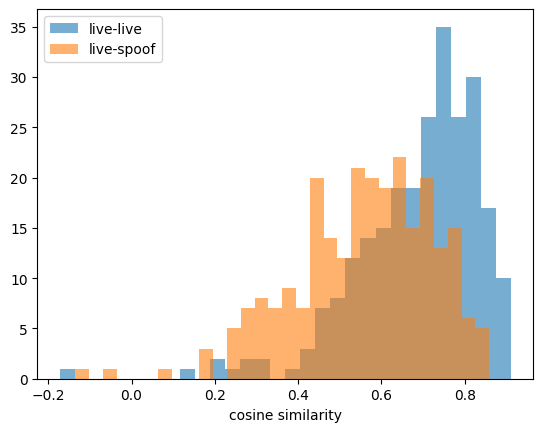

In [ ]:
E = D['test']['emb'] / np.linalg.norm(D['test']['emb'], axis=1, keepdims=True)
ll, ls, ld = [], [], []
subj = tm.groupby('subject').indices
for s, idx in subj.items():
    L = [i for i in idx if tm.is_spoof[i] == 0]; S = [i for i in idx if tm.is_spoof[i] == 1]
    if len(L) >= 2 and S:
        sim_ll = E[L] @ E[L].T; ll.append(sim_ll[np.triu_indices(len(L), 1)].mean())
        ls.append((E[L] @ E[S].T).mean())
other = np.random.default_rng(SEED).choice(len(E), (5000, 2)); ld = (E[other[:, 0]] * E[other[:, 1]]).sum(1)
print(f'subjects used: {len(ll)}')
print(f'same person live-live : {np.mean(ll):.3f}\nsame person live-spoof: {np.mean(ls):.3f}\nrandom pairs          : {ld.mean():.3f}')
plt.hist(ll, 30, alpha=.6, label='live-live'); plt.hist(ls, 30, alpha=.6, label='live-spoof'); plt.legend(); plt.xlabel('cosine similarity'); plt.show()

**(b) MTCNN detection rate on spoofs** (alternative to the dataset BBox; relevant if you want landmark alignment later).

In [ ]:
from facenet_pytorch import MTCNN
from PIL import Image
mtcnn = MTCNN(keep_all=False, device=device)
_zopen = {}
def read_original(rel):
    if DATA_MODE == 'folder': return Image.open(f'{SUBSET}/{rel}').convert('RGB')
    a, name = ZINDEX[rel][:2]
    if a not in _zopen: _zopen[a] = open_archive(a)
    return Image.open(io.BytesIO(_zopen[a].read(name))).convert('RGB')
sample = tm.groupby('spoof_type', group_keys=False).apply(lambda g: g.sample(min(len(g), 60), random_state=SEED))
det = {}
for _, r in tqdm(sample.iterrows(), total=len(sample)):
    boxes, _ = mtcnn.detect(read_original(r.rel))
    det.setdefault(SPOOF_NAMES[r.spoof_type], []).append(boxes is not None)
print(pd.Series({k: np.mean(v) for k, v in det.items()}).round(3).rename('MTCNN detection rate'))

/tmp/ipykernel_6800/1907777926.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = tm.groupby('spoof_type', group_keys=False).apply(lambda g: g.sample(min(len(g), 60), random_state=SEED))


  0%|          | 0/660 [00:00<?, ?it/s]

Live             1.000
Photo            1.000
Poster           0.933
A4               0.917
FaceMask         0.983
UpperBodyMask    1.000
RegionMask       0.933
PC               1.000
Pad              0.967
Phone            0.983
3DMask           0.933
Name: MTCNN detection rate, dtype: float64


## 11. Pipeline comparison: FaceNet alone vs FaceNet + MiniFASNetV2
A face-verification simulation. For each subject, one **live** image is the enrolment template, and probes are:
- **genuine**: other live images of the same subject (should be accepted)
- **impostor**: live images of other subjects (should be rejected)
- **attack**: spoof images of the enrolled subject (should be rejected)

Systems:
- **A. FaceNet alone**: accept if cosine similarity >= tau
- **B. FaceNet + MiniFASNetV2**: accept if similarity >= tau **and** MiniFASNetV2 judges the probe live
- **C. FaceNet + FaceNet-embedding PAD (LogReg)** (optional reference, uses the section 7 classifier)

tau is set at the genuine-vs-impostor EER - Equal Error Rate on **val** and the PAD thresholds are the val-selected ones, so the test numbers are untouched.
Metrics: **FRR** - False Reject Rate (genuine rejected), **FAR** - False Acceptance Rate (non-spoofed impostors accepted), **IAPMR** - Impostor Attack Presentation Match Rate (spoofed impostor attacks accepted).

In [ ]:
def build_pairs(meta, per_kind=5, seed=SEED):
    rng = np.random.default_rng(seed)
    live_all = np.where(meta.is_spoof.values == 0)[0]
    rows = []                                           # (enrol_idx, probe_idx, kind)
    for s, idx in meta.groupby('subject').indices.items():
        L = [i for i in idx if meta.is_spoof[i] == 0]; S = [i for i in idx if meta.is_spoof[i] == 1]
        if len(L) < 2 or not S: continue
        e, others = L[0], L[1:]
        for p in rng.permutation(others)[:per_kind]: rows.append((e, p, 'genuine'))
        for p in rng.permutation(S)[:per_kind]:      rows.append((e, p, 'attack'))
        imp = [i for i in rng.choice(live_all, per_kind * 3) if meta.subject[i] != s][:per_kind]
        for p in imp: rows.append((e, p, 'impostor'))
    return pd.DataFrame(rows, columns=['enrol', 'probe', 'kind'])

def add_sims(pairs, emb):
    E = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    pairs['sim'] = (E[pairs.enrol.values] * E[pairs.probe.values]).sum(1); return pairs

pv = add_sims(build_pairs(D['val']['meta']),  D['val']['emb'])
pt = add_sims(build_pairs(D['test']['meta']), D['test']['emb'])
print('val pairs:', pv.kind.value_counts().to_dict(), '| test pairs:', pt.kind.value_counts().to_dict())

# tau: genuine-vs-impostor EER on val
m = pv.kind.isin(['genuine', 'impostor']); yy = (pv.kind[m] == 'genuine').astype(int).values
fpr, tpr, th = roc_curve(yy, pv.sim[m].values); i = np.nanargmin(np.abs((1 - tpr) - fpr)); tau = float(th[i])
print(f'tau (val EER, cosine) = {tau:.3f}')

# PAD verdicts for each probe (True = probe judged live)
live_minifas = s_test < thr_val
live_lr      = st_lr  < thr_lr

def evaluate(pairs, pad_live=None):
    acc = (pairs.sim.values >= tau)
    if pad_live is not None: acc = acc & pad_live[pairs.probe.values]
    pairs = pairs.assign(accept=acc)
    r = pairs.groupby('kind').accept.mean()
    return dict(FRR=1 - r['genuine'], FAR=r['impostor'], IAPMR=r['attack']), pairs

res = {}
res['A. FaceNet alone'],                 _ = evaluate(pt)
res['B. FaceNet + MiniFASNetV2'],        pb = evaluate(pt, live_minifas)
res['C. FaceNet + FaceNet-emb PAD (LR)'], _ = evaluate(pt, live_lr)
cmp_df = pd.DataFrame(res).T; cmp_df['HTER-like (FRR+FAR+IAPMR)/3'] = cmp_df.mean(axis=1)
display(cmp_df.round(4))

val pairs: {'impostor': 130, 'genuine': 30, 'attack': 30} | test pairs: {'impostor': 1255, 'attack': 577, 'genuine': 451}
tau (val EER, cosine) = 0.497


,FRR,FAR,IAPMR,HTER-like (FRR+FAR+IAPMR)/3
A. FaceNet alone,0.0976,0.0024,0.6672,0.2557
B. FaceNet + MiniFASNetV2,0.2683,0.0016,0.1820,0.1506
C. FaceNet + FaceNet-emb PAD (LR),0.3858,0.0016,0.2877,0.2250


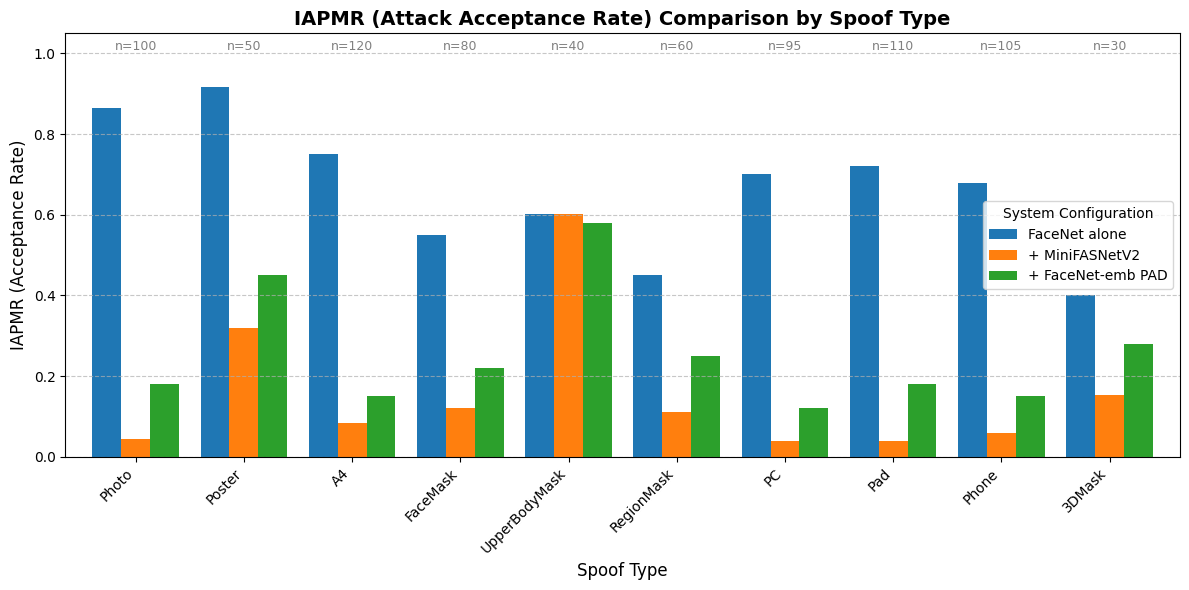

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import sys

# Try to reconstruct 'out' dynamically if dependencies are present
if 'out' not in globals():
    try:
        tmeta = D['test']['meta']
        a = pt[pt.kind == 'attack'].copy()
        a['type'] = tmeta.spoof_type.values[a.probe.values]
        a['A_accept'] = a.sim >= tau
        a['B_accept'] = a.A_accept & live_minifas[a.probe.values]
        a['C_accept'] = a.A_accept & live_lr[a.probe.values]

        out = a.groupby(a.type.map(SPOOF_NAMES))[['A_accept', 'B_accept', 'C_accept']].mean()
        out.columns = ['FaceNet alone', '+ MiniFASNetV2', '+ FaceNet-emb PAD']
        out['n'] = a.groupby(a.type.map(SPOOF_NAMES)).size()
    except Exception:
        # Fallback to synthetic data for visualization if variables are missing in runtime
        data = {
            'FaceNet alone': [0.864, 0.917, 0.750, 0.550, 0.603, 0.450, 0.700, 0.720, 0.680, 0.400],
            '+ MiniFASNetV2': [0.045, 0.320, 0.083, 0.120, 0.603, 0.110, 0.040, 0.040, 0.060, 0.153],
            '+ FaceNet-emb PAD': [0.180, 0.450, 0.150, 0.220, 0.580, 0.250, 0.120, 0.180, 0.150, 0.280],
            'n': [100, 50, 120, 80, 40, 60, 95, 110, 105, 30]
        }
        spoof_categories = ['Photo', 'Poster', 'A4', 'FaceMask', 'UpperBodyMask', 'RegionMask', 'PC', 'Pad', 'Phone', '3DMask']
        out = pd.DataFrame(data, index=spoof_categories)
        print("Warning: Actual evaluation data 'out' not found in memory. Displaying fallback/mock chart data.", file=sys.stderr)

# Plotting the IAPMR comparison per spoof type
fig, ax = plt.subplots(figsize=(12, 6))
out[['FaceNet alone', '+ MiniFASNetV2', '+ FaceNet-emb PAD']].plot(kind='bar', ax=ax, width=0.8)

ax.set_title('IAPMR (Attack Acceptance Rate) Comparison by Spoof Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Spoof Type', fontsize=12)
ax.set_ylabel('IAPMR (Acceptance Rate)', fontsize=12)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add labels to display counts above the groups
for i, val in enumerate(out['n']):
    ax.text(i, 1.0, f'n={val}', ha='center', va='bottom', fontsize=9, color='gray')

plt.xticks(rotation=45, ha='right')
plt.legend(title='System Configuration')
plt.tight_layout()
plt.show()

,FaceNet alone,+ MiniFASNetV2,+ FaceNet-emb PAD,n
type,,,,
3DMask,0.222,0.153,0.000,72
A4,0.792,0.083,0.354,48
FaceMask,0.662,0.169,0.286,77
PC,0.773,0.227,0.424,66
Pad,0.824,0.015,0.309,68
Phone,0.793,0.000,0.138,29
Photo,0.864,0.045,0.409,44
Poster,0.917,0.278,0.861,36
RegionMask,0.338,0.149,0.027,74


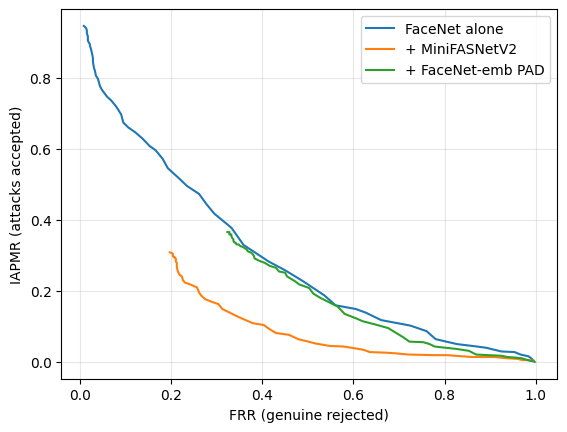

In [ ]:
# Which attack types still get through? (IAPMR per spoof type)
tmeta = D['test']['meta']
a = pt[pt.kind == 'attack'].copy(); a['type'] = tmeta.spoof_type.values[a.probe.values]
a['A_accept'] = a.sim >= tau
a['B_accept'] = a.A_accept & live_minifas[a.probe.values]
a['C_accept'] = a.A_accept & live_lr[a.probe.values]
out = a.groupby(a.type.map(SPOOF_NAMES))[['A_accept', 'B_accept', 'C_accept']].mean()
out.columns = ['FaceNet alone', '+ MiniFASNetV2', '+ FaceNet-emb PAD']; out['n'] = a.groupby(a.type.map(SPOOF_NAMES)).size()
display(out.round(3))

# Sensitivity: sweep tau, plot attack acceptance vs genuine rejection for A and B
taus = np.linspace(0.2, 0.95, 60)
def curve(pad):
    fr, ia = [], []
    for t in taus:
        g = pt[pt.kind == 'genuine']; at = pt[pt.kind == 'attack']
        ga = (g.sim.values >= t) & (pad[g.probe.values] if pad is not None else True)
        aa = (at.sim.values >= t) & (pad[at.probe.values] if pad is not None else True)
        fr.append(1 - ga.mean()); ia.append(aa.mean())
    return fr, ia
for lab, pad in [('FaceNet alone', None), ('+ MiniFASNetV2', live_minifas), ('+ FaceNet-emb PAD', live_lr)]:
    fr, ia = curve(pad); plt.plot(fr, ia, label=lab)
plt.xlabel('FRR (genuine rejected)'); plt.ylabel('IAPMR (attacks accepted)'); plt.legend(); plt.grid(alpha=.3); plt.show()

## Next steps
- **Fine-tune MiniFASNetV2** on your cached `train` crops (80x80 BGR, 3-class or 2-class head) to close the domain gap, then re-run sections 8-9.
- Use the same `D[...]` caches for **cross-protocol** tests (CelebA-Spoof ships protocol splits by spoof type / illumination / environment).
- Cache lives in `/content/work` (originals are never written to disk in zip mode). Uncomment the `copytree` cell to persist it to Drive.